# Notebook n°5 : Comparaison des modèles

### Problématique

Dans quelle mesure la structure du réseau TGV est-elle associée à la régularité des liaisons, et peut-on exploiter cette structure pour améliorer la prédiction des retards ?

## 1. Objectifs

Dans ce notebook, nous allons comparer quatre modèles de Machine Learning pour prédire le taux de retard des liaisons TGV.

Notre objectif est de voir si l'ajout des caractéristiques du réseau, étudiées dans le notebook 03, et des clusters obtenus dans le notebook 04 permet d'améliorer les prédictions par rapport à un modèle utilisant uniquement les variables classiques.

Pour cela, nous allons tester quatre modèles :

- Modèle A : modèle de référence, avec uniquement les variables historiques.
- Modèle B : modèle de référence auquel on ajoute les caractéristiques du graphe, notamment la centralité des gares.
- Modèle C : modèle de référence auquel on ajoute le cluster de chaque liaison, obtenu grâce au clustering du notebook 04.
- Modèle D : modèle qui combine les variables historiques, les caractéristiques du graphe et les clusters.

Nous comparerons ensuite leurs résultats pour voir si ces nouvelles informations permettent de mieux prédire les retards.

## I. Préparation des données

Nous repartons du fichier parquet préparé par l'ETL (data/processed/sncf.parquet) et nous utilisons les fonctions du module projet_kit_data.ml.baseline pour créer les variables historiques à partir des 12 mois précédents.

Nous ajoutons ensuite à chaque observation le cluster obtenu dans le notebook 04, en regroupant les deux sens d'une même liaison. Nous ajoutons aussi les caractéristiques du graphe calculées avec le module projet_kit_data.graph. Celui-ci construit un réseau orienté et calcule cinq indicateurs pour chaque gare : le degré entrant, le degré sortant, le degré total, la centralité d'intermédiarité et le PageRank.

Enfin, nous séparons les données chronologiquement en deux groupes, un pour l'entraînement et un pour le test, grâce à la fonction chronological_split. Cela permet d'éviter qu'un même mois se retrouve dans les deux groupes.

In [1]:
"""Chargement et préparation des données pour comparer les quatre modèles."""

from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

# On retrouve le dossier principal du projet
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

# On ajoute le dossier src pour accéder aux fonctions du projet
sys.path.insert(0, str(project_root / "src"))

from projet_kit_data.ml.baseline import (
    prepare_baseline_data,
    build_baseline_dataset,
    chronological_split,
)
from projet_kit_data.comparaison import (
    load_cluster_features,
    add_cluster_to_dataset,
    train_and_evaluate,
    format_comparison_table,
)

SEED = 42

# On charge les données préparées par l'ETL
data_etl = pd.read_parquet(project_root / "data" / "processed" / "sncf.parquet")


data_ml = prepare_baseline_data(data_etl)
dataset = build_baseline_dataset(data_ml, window_months=12)

# On affiche le nombre d'observations et la période étudiée
print(f"Observations : {len(dataset)}")
print(f"Période : {dataset['date'].min().date()} → {dataset['date'].max().date()}")


Observations : 11347
Période : 2019-01-01 → 2026-09-01


In [2]:

# On ajoute au dataset les clusters obtenus dans le notebook 04
clusters = load_cluster_features(
    project_root / "data" / "processed" / "clusters_liaisons.csv"
)
dataset = add_cluster_to_dataset(dataset, clusters)

# On garde uniquement les observations qui ont un cluster
dataset = dataset.dropna(subset=["cluster"]).copy()
dataset["cluster"] = dataset["cluster"].astype(int)

# On affiche le nombre d'observations et leur répartition par cluster
print(f"Observations avec cluster : {len(dataset)}")
print("\nRépartition par cluster :")
print(dataset["cluster"].value_counts().sort_index())


Observations avec cluster : 11347

Répartition par cluster :
cluster
0    4658
1    3534
2     709
3    2446
Name: count, dtype: int64


In [3]:
# Ajout des 10 features de graphe via le module comparaison
from projet_kit_data.comparaison import add_graph_features

dataset = add_graph_features(dataset)

print(f"Features de graphe ajoutees : 10 colonnes (5 par gare x depart/arrivee)")

Features de graphe ajoutees : 10 colonnes (5 par gare x depart/arrivee)


## II. Entraînement des quatre modèles

Nous allons entraîner quatre modèles avec l'algorithme HistGradientBoostingRegressor. Ils utilisent tous les mêmes variables catégorielles, à savoir le service, la gare de départ, la gare d'arrivée et le mois. La différence entre les modèles se trouve dans les variables supplémentaires que nous leur ajoutons.

Le modèle A sert de référence et utilise uniquement les variables historiques calculées sur 12 mois. Le modèle B reprend ces mêmes variables en ajoutant les dix caractéristiques du graphe. Le modèle C utilise les variables historiques avec le cluster de chaque liaison, tandis que le modèle D combine toutes ces informations, c'est-à-dire les variables historiques, les caractéristiques du graphe et les clusters.

Nous allons ensuite comparer leurs performances pour voir si les caractéristiques du réseau et les clusters permettent d'améliorer les prédictions, et si leur combinaison apporte un avantage supplémentaire.

In [4]:
train, _, test = chronological_split(dataset)

print(f"Train : {len(train)} observations ({train['date'].min().date()} → {train['date'].max().date()})")
print(f"Test  : {len(test)} observations ({test['date'].min().date()} → {test['date'].max().date()})")

Train : 7844 observations (2019-01-01 → 2024-05-01)
Test  : 1857 observations (2025-07-01 → 2026-09-01)


In [5]:
# Variables de base communes aux quatre modeles (categorielles + mois)
BASE_FEATURES = ["service", "departure", "arrival", "month"]

# Features numeriques par groupe
HISTORIC_FEATURES = [
    "historical_delay_rate_15",
    "historical_circulated",
    "historical_observations",
]

GRAPH_FEATURES = [
    "depart_in_degree", "depart_out_degree", "depart_total_degree",
    "depart_betweenness", "depart_pagerank",
    "arrivee_in_degree", "arrivee_out_degree", "arrivee_total_degree",
    "arrivee_betweenness", "arrivee_pagerank",
]

CLUSTER_FEATURES = ["cluster"]

TARGET = "delay_rate_15"

# Les quatre configurations a comparer
configurations = {
    "A - Baseline": HISTORIC_FEATURES,
    "B - Baseline + graphe": HISTORIC_FEATURES + GRAPH_FEATURES,
    "C - Baseline + cluster": HISTORIC_FEATURES + CLUSTER_FEATURES,
    "D - Baseline + graphe + cluster": HISTORIC_FEATURES + GRAPH_FEATURES + CLUSTER_FEATURES,
}

resultats = []
for nom, extras in configurations.items():
    print(f"Entrainement du modele {nom}...")
    resultat = train_and_evaluate(train, test, BASE_FEATURES, extras, TARGET, nom)
    resultats.append(resultat)
    print(f"  MAE = {resultat['mae']:.4f}  |  RMSE = {resultat['rmse']:.4f}")

Entrainement du modele A - Baseline...
  MAE = 0.0438  |  RMSE = 0.0679
Entrainement du modele B - Baseline + graphe...
  MAE = 0.0436  |  RMSE = 0.0678
Entrainement du modele C - Baseline + cluster...
  MAE = 0.0435  |  RMSE = 0.0674
Entrainement du modele D - Baseline + graphe + cluster...
  MAE = 0.0435  |  RMSE = 0.0675


## III. Résultats et validation

Nous allons comparer les quatre modèles à l'aide de trois indicateurs : la MAE, la RMSE et le R².

Nous allons également comparer leurs résultats avec ceux d'un modèle très simple, qui prédit toujours le taux de retard moyen des données d'entraînement.

Cela nous permettra de vérifier si nos modèles apportent réellement une amélioration par rapport à cette prédiction de référence, et pas seulement de voir lequel des quatre obtient les meilleurs résultats.

In [6]:
# On ajoute le R² dans resultats avant de formater
from sklearn.metrics import r2_score

for res in resultats:
    extras = configurations[res["modele"]]
    columns = BASE_FEATURES + extras
    predictions = res["modele_entraine"].predict(test[columns])
    res["r2"] = r2_score(test[TARGET], predictions)

# Tableau comparatif avec MAE, RMSE, R²
tableau = pd.DataFrame([
    {
        "modele": r["modele"],
        "mae_pts": round(r["mae"] * 100, 3),
        "rmse_pts": round(r["rmse"] * 100, 3),
        "r2": round(r["r2"], 4),
        "amelioration_mae_vs_A": round(
            (resultats[0]["mae"] - r["mae"]) * 100, 3
        ),
    }
    for r in resultats
]).sort_values("mae_pts").reset_index(drop=True)

tableau

,modele,mae_pts,rmse_pts,r2,amelioration_mae_vs_A
0,D - Baseline + graphe + cluster,4.347,6.751,0.4579,0.036
1,C - Baseline + cluster,4.348,6.741,0.4595,0.034
2,B - Baseline + graphe,4.365,6.780,0.4532,0.018
3,A - Baseline,4.383,6.791,0.4513,0.000


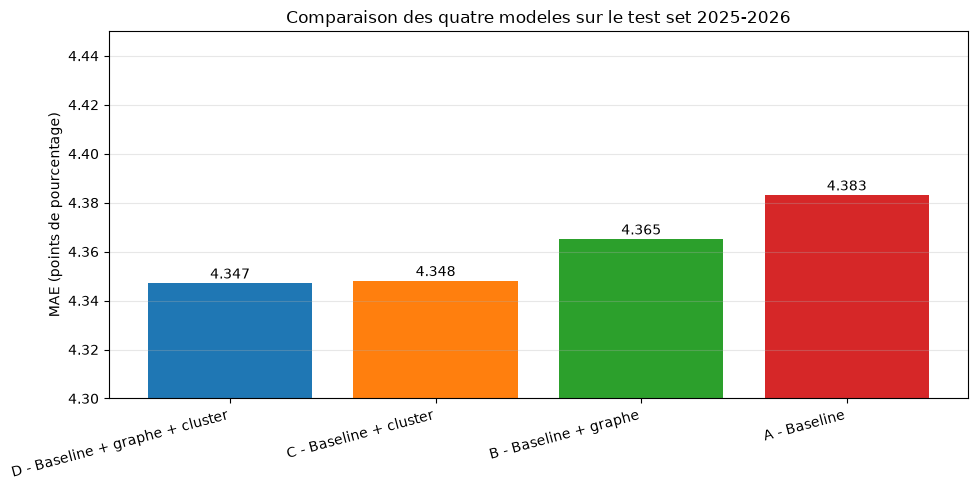

In [7]:
%matplotlib inline
fig, ax = plt.subplots(figsize=(10, 5))

x = range(len(tableau))
couleurs = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
ax.bar(x, tableau["mae_pts"], color=couleurs)
ax.set_xticks(x)
ax.set_xticklabels(tableau["modele"], rotation=15, ha="right")
ax.set_ylabel("MAE (points de pourcentage)")
ax.set_title("Comparaison des quatre modeles sur le test set 2025-2026")
ax.grid(axis="y", alpha=0.3)
ax.set_ylim(4.3, 4.45)

for i, v in enumerate(tableau["mae_pts"]):
    ax.text(i, v + 0.002, f"{v:.3f}", ha="center")

plt.tight_layout()
plt.show()

In [8]:
# Modele naif pour comparaison et R² des quatre modeles entraines
from projet_kit_data.comparaison import compute_naive_baseline
from sklearn.metrics import r2_score

# Modele naif via la fonction du module
baseline = compute_naive_baseline(train, test, TARGET)
print("Modele naif (predire la moyenne):")
print(f"  MAE = {baseline['mae_pts']} pts")
print(f"  R2  = {baseline['r2']}")
print()

# R² pour chaque modele entraine
print("Modeles entraines:")
for res in resultats:
    extras = configurations[res["modele"]]
    columns = BASE_FEATURES + extras
    predictions = res["modele_entraine"].predict(test[columns])
    r2 = r2_score(test[TARGET], predictions)
    res["r2"] = r2
    print(f"  {res['modele']}: R2 = {r2:.4f}")

Modele naif (predire la moyenne):
  MAE = 6.719 pts
  R2  = -0.2518

Modeles entraines:
  A - Baseline: R2 = 0.4513
  B - Baseline + graphe: R2 = 0.4532
  C - Baseline + cluster: R2 = 0.4595
  D - Baseline + graphe + cluster: R2 = 0.4579


## IV. Erreur par cluster

Pour mieux comprendre les différences entre les modèles, nous allons comparer leur MAE pour chaque cluster.

Cela nous permettra de voir si l'ajout des caractéristiques du réseau améliore davantage les prédictions pour certains groupes, notamment le cluster 2, qui regroupe des liaisons plus longues et présente le taux de retard le plus élevé.

In [9]:

# On calcule la MAE de chaque modèle pour chaque cluster
# On utilise la fonction compute_errors_by_group du module comparaison

from projet_kit_data.comparaison import compute_errors_by_group

performances = {}

for res in resultats:
    extras = configurations[res["modele"]]
    columns = BASE_FEATURES + extras

    mae_par_cluster = compute_errors_by_group(
        res["modele_entraine"], test, columns, TARGET, "cluster"
    )

    performances[res["modele"]] = mae_par_cluster

# On regroupe les résultats dans un tableau pour comparer les modèles
tableau_perf = pd.DataFrame(performances)
tableau_perf


,A - Baseline,B - Baseline + graphe,C - Baseline + cluster,D - Baseline + graphe + cluster
groupe,,,,
0,3.576,3.549,3.558,3.529
1,4.292,4.269,4.247,4.255
2,11.420,11.408,11.296,11.442
3,4.210,4.214,4.184,4.182


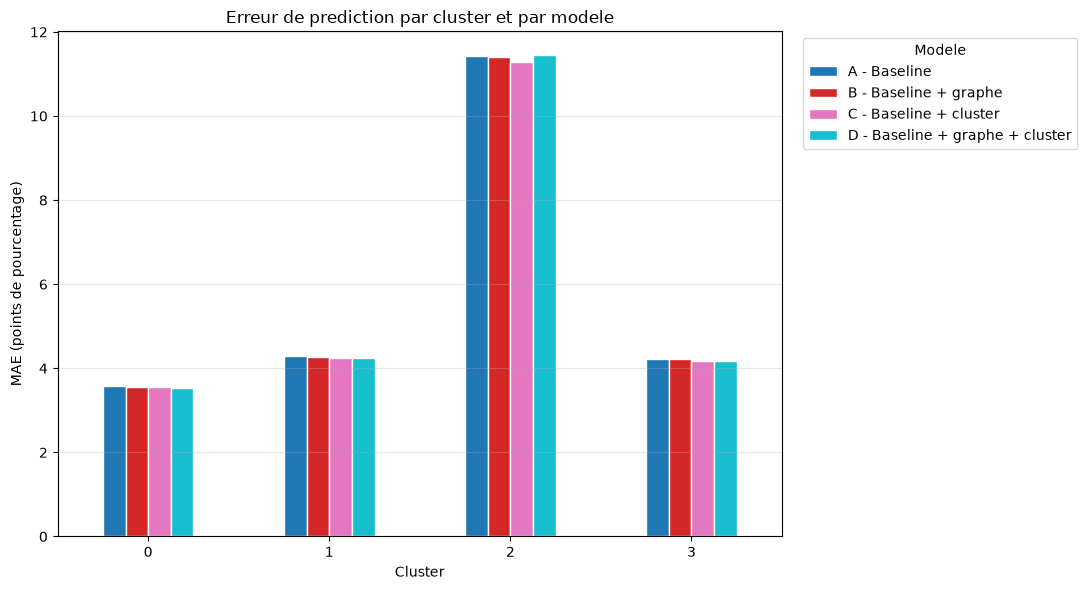

In [10]:
# Comparaison visuelle par cluster
%matplotlib inline
fig, ax = plt.subplots(figsize=(11, 6))
tableau_perf.plot(kind="bar", ax=ax, colormap="tab10", edgecolor="white")
ax.set_ylabel("MAE (points de pourcentage)")
ax.set_xlabel("Cluster")
ax.set_title("Erreur de prediction par cluster et par modele")
ax.legend(title="Modele", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.3)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()

## Finalement

Les quatre modèles obtiennent un R² autour de 0,45. Cela montre qu'ils arrivent à expliquer une partie des différences de taux de retard, même si certains événements comme les grèves, les problèmes météo ou les pannes restent difficiles à prévoir.

On remarque aussi que nos modèles donnent de meilleurs résultats que le modèle naïf, qui prédit toujours la moyenne. Leur MAE est d'environ 4,35 points, contre 6,72 points pour le modèle naïf, soit une amélioration d'environ 35 %.

Parmi les quatre modèles, le modèle C, qui utilise les clusters en plus des variables historiques, obtient le meilleur R². Ses résultats sont cependant très proches de ceux du modèle D, qui ajoute également les caractéristiques du graphe. Cela pourrait signifier que les clusters et les caractéristiques du graphe apportent en partie des informations similaires, et que l'ajout des deux n'est pas forcément plus intéressant que l'utilisation des clusters seuls.

Pour revenir à notre problématique, nous avons montré que la structure du réseau TGV est associée à la régularité des liaisons et que certaines de ses caractéristiques peuvent être utilisées pour améliorer la prédiction des retards. Parmi les méthodes testées, le clustering non supervisé semble être le plus intéressant. Cependant, le gain reste assez faible, puisque le modèle de référence, qui utilise uniquement l'historique des 12 derniers mois, atteint déjà un R² proche de 0,45.

Pour améliorer notre travail, nous pourrions ajouter d'autres informations comme la météo, les grèves ou les travaux prévus sur le réseau. Il serait aussi intéressant de tester des méthodes permettant d'obtenir une plage de valeurs possibles plutôt qu'une seule prédiction, ou encore de créer un modèle spécifique aux liaisons internationales, qui restent les plus difficiles à prédire.